# 📊 BÁO CÁO PHÂN TÍCH KHÁM PHÁ DỮ LIỆU THÔ (RAW-FIRST EDA & DATA STORYLINE)
## NGUỒN DỮ LIỆU: VIECLAM24H (`https://vieclam24h.vn`)

> **Dự án:** Phân tích thị trường lao động IT và nhu cầu kỹ năng nghề nghiệp tại Việt Nam (VN-IT-Job-Mining)  
> **Phân loại nguồn:** Sàn việc làm phổ thông & Doanh nghiệp nội địa (Local Job Portal)  
> **Nguyên tắc chỉ đạo:** **Inquiry-Driven Framework & Zero Information Loss** theo cẩm nang [01_huong_dan_eda_nhom_3_nguoi.md](file:///run/media/billtran/Data/Archduker/Study/UTH/Core/DataMining/VN-IT-Job-Mining/docs/tasks/01_huong_dan_eda_nhom_3_nguoi.md).  
> **Mục tiêu cốt lõi:** Bóc tách toàn diện 5 trụ cột chất lượng dữ liệu thô (Độ hoàn thiện, Tính hợp lệ, Tính duy nhất, Hình thái phân phối/Ngoại lai, và Độ thiên lệch/Mất cân bằng) để làm cơ sở khoa học thiết kế chuỗi **Pre-processing Pipeline** và đối chiếu khoảng trống dữ liệu theo [02_huong_dan_insight_va_so_sanh_nguon.md](file:///run/media/billtran/Data/Archduker/Study/UTH/Core/DataMining/VN-IT-Job-Mining/docs/tasks/02_huong_dan_insight_va_so_sanh_nguon.md).  
> **Quy ước kỹ thuật:** Trực quan hóa 100% inline trong notebook (`plt.show()`), không lưu file ảnh bên ngoài.

---

### 📋 Cấu Trúc Bản Ghi JSON Thô Mẫu Đại Diện (Full Raw Envelope: Metadata + Payload)
Dưới đây là một bản ghi dữ liệu thô tiêu biểu thu thập trực tiếp từ sàn **Vieclam24h** theo chuẩn **Zero Information Loss**. Bản ghi gồm hai phần phong bì chuẩn hóa:
1. **`metadata` (Phong bì truy vết & kiểm định toàn vẹn):** Lưu trữ mã định danh `job_id`, URL nguồn gốc `source_url`, thời điểm cào ISO-8601 `scraped_at`, phiên bản scraper `scraper_version`, và chữ ký băm mật mã SHA-256 (`content_hash`) phục vụ cơ chế Change Data Capture (CDC).
2. **`raw_payload` (Dữ liệu tuyển dụng bóc tách nguyên bản):** Giữ nguyên vẹn 100% các trường thuộc tính, mảng lồng nhau, thẻ tag, định dạng lương tự do, và các dấu hiệu null trá hình trước khi đưa vào chuỗi tiền xử lý:

```json
{
  "metadata": {
    "job_id": "200967998",
    "source": "vieclam24h",
    "source_url": "https://vieclam24h.vn/it-phan-cung-mang/nhan-vien-ky-thuat-tin-hoc-c7p210000186id200967998.html",
    "scraped_at": "2026-10-20T12:51:16.377010+00:00",
    "scraper_version": "2.0.0",
    "version": 1,
    "content_hash": "0bc13a287aa0a7316dfa2dbd704a7c7e7ef9e17e850014b61b42f9c79ae7ce59",
    "canonical_hash": "0bc13a287aa0a7316dfa2dbd704a7c7e7ef9e17e850014b61b42f9c79ae7ce59"
  },
  "raw_payload": {
    "title": "Nhân Viên Kỹ Thuật Tin Học / IT Support",
    "salary": "10 - 16 triệu",
    "deadline": "18/11/2026",
    "location_summary": "Đồng Nai",
    "experience_summary": "1 năm",
    "description": [
      "Lắp ráp, cài đặt, bảo trì và sửa chữa máy tính, laptop và hệ thống mạng nội bộ.",
      "Cài đặt, bảo trì máy in, máy photocopy và thiết bị ngoại vi văn phòng.",
      "Lắp đặt, cấu hình và bảo trì hệ thống camera giám sát an ninh.",
      "Hỗ trợ kỹ thuật tại chỗ và từ xa cho người dùng khách hàng doanh nghiệp."
    ],
    "requirements": [
      "Tốt nghiệp Trung cấp/Cao đẳng trở lên chuyên ngành Công nghệ thông tin hoặc Điện tử viễn thông.",
      "Có kiến thức thực tế về phần cứng máy tính, hệ điều hành Windows/Linux và mạng LAN/WAN.",
      "Trung thực, chịu khó, có trách nhiệm và giao tiếp lịch sự."
    ],
    "benefits": [
      "Mức lương: 10.000.000 - 16.000.000 VNĐ (thoả thuận thêm theo năng lực khi phỏng vấn).",
      "Hưởng đầy đủ chế độ BHXH, BHYT, BHTN theo Luật Lao động hiện hành.",
      "Tham gia các đợt đào tạo nâng cao tay nghề định kỳ và thưởng dự án."
    ],
    "working_time": "Thứ 2 - Thứ 7 (8:00 - 17:00), Chủ nhật nghỉ",
    "working_address": "Tổ 12B, khu 2, ấp 7, Xã An Phước, Huyện Long Thành, Tỉnh Đồng Nai",
    "keywords": [
      "kỹ thuật viên tin học",
      "IT Helpdesk",
      "IT Support",
      "bảo trì máy tính",
      "quản trị mạng LAN"
    ],
    "general_info.posted_date": "19/10/2026",
    "general_info.level": "Nhân viên",
    "general_info.working_type": "Toàn thời gian cố định"
  }
}
```


In [1]:
import os
import sys
import json
import re
import warnings
from pathlib import Path
from collections import Counter

warnings.filterwarnings("ignore")

# 1. Thiết lập môi trường dự án & Thư viện phân tích định lượng
p = Path.cwd().resolve()
while not (p / "run.py").is_file() and p != p.parent:
    p = p.parent
PROJECT_ROOT = p
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import RobustScaler, StandardScaler
from IPython.display import display

# Nạp module Lakehouse Loader thống nhất (Zero Information Loss)
from scripts.lakehouse_loader import load_raw_source_dataframe

# Cấu hình trực quan hóa inline chuẩn mực
sns.set_theme(style="whitegrid")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

SOURCE_KEY = "vieclam24h"
DISPLAY_NAME = "Vieclam24h"
print(f"✅ Đã khởi tạo thành công môi trường EDA thô cho nguồn: {DISPLAY_NAME} ({SOURCE_KEY})")


✅ Đã khởi tạo thành công môi trường EDA thô cho nguồn: Vieclam24h (vieclam24h)


In [2]:
# 2. Nạp toàn bộ dữ liệu snapshot thô từ Lakehouse
df_raw, audit_meta = load_raw_source_dataframe(SOURCE_KEY, auto_sync=False)

N_TOTAL = len(df_raw)
N_COLS = df_raw.shape[1]

print("=" * 80)
print(f"📦 TẬP DỮ LIỆU THÔ NGUỒN {DISPLAY_NAME.upper()}:")
print(f"   - Tổng số bản ghi snapshot cào được: {N_TOTAL:,} bài đăng")
print(f"   - Tổng số trường dữ liệu gốc (Raw Columns): {N_COLS} thuộc tính")
print(f"   - Danh sách 10 trường đầu tiên: {df_raw.columns.tolist()[:10]}")
print("=" * 80)

# 2.1. Đọc và hiển thị phong bì dữ liệu thô nguyên bản (Raw Envelope: metadata + raw_payload)
raw_files = list((PROJECT_ROOT / "data" / SOURCE_KEY).glob("**/*.json"))
real_envelope = None
for fp in raw_files:
    if "url_ledger" not in str(fp) and "manifest" not in str(fp):
        try:
            with open(fp, "r", encoding="utf-8") as f:
                c = json.load(f)
            if isinstance(c, list) and len(c) > 0: c = c[0]
            if isinstance(c, dict) and "metadata" in c:
                real_envelope = c
                break
        except Exception:
            pass

print("📦 1. LAKEHOUSE LEDGER AUDIT METADATA:")
print(json.dumps(audit_meta, indent=2, ensure_ascii=False, default=str))

print("=" * 80)
if real_envelope:
    print(f"🔍 2. BẢN GHI JSON THÔ NGUYÊN BẢN CẢ METADATA & RAW PAYLOAD (NGUỒN {DISPLAY_NAME.upper()}):")
    raw_p = real_envelope.get("raw_payload", {})
    clean_p = {k: v for k, v in raw_p.items() if k not in ['raw_html', 'container_content', 'signed_content.payload', 'signed_content.signatures']}
    display_envelope = {
        "metadata": real_envelope.get("metadata", {}),
        "raw_payload": {k: clean_p[k] for k in list(clean_p.keys())[:12]}
    }
    print(json.dumps(display_envelope, ensure_ascii=False, indent=2, default=str))
else:
    title_col = 'title' if 'title' in df_raw.columns else ('job-title' if 'job-title' in df_raw.columns else 'jobTitle')
    cand = df_raw[~df_raw[title_col].isna()] if title_col in df_raw.columns else df_raw
    sample_dict = cand.iloc[0].dropna().to_dict() if not cand.empty else df_raw.iloc[0].dropna().to_dict()
    sample_clean = {k: v for k, v in sample_dict.items() if k not in ['raw_html', 'container_content', 'signed_content.payload', 'signed_content.signatures']}
    print("🔍 2. BẢN GHI JSON THÔ TRÍCH XUẤT TỪ LAKEHOUSE:")
    print(json.dumps({"metadata": {"source": SOURCE_KEY, "status": "RAW_AS_IS"}, "raw_payload": {k: sample_clean[k] for k in list(sample_clean.keys())[:12]}}, ensure_ascii=False, indent=2, default=str))
print("=" * 80)

df_raw.head(3)


📦 TẬP DỮ LIỆU THÔ NGUỒN VIECLAM24H:
   - Tổng số bản ghi snapshot cào được: 619 bài đăng
   - Tổng số trường dữ liệu gốc (Raw Columns): 21 thuộc tính
   - Danh sách 10 trường đầu tiên: ['title', 'salary', 'deadline', 'location_summary', 'experience_summary', 'description', 'requirements', 'benefits', 'working_time', 'working_address']
📦 1. LAKEHOUSE LEDGER AUDIT METADATA:
{
  "total_discovered": 622,
  "done_count": 622,
  "pending_count": 0,
  "status_breakdown": {
    "DONE": 622
  },
  "sync_info": {}
}
🔍 2. BẢN GHI JSON THÔ NGUYÊN BẢN CẢ METADATA & RAW PAYLOAD (NGUỒN VIECLAM24H):
{
  "metadata": {
    "job_id": "200967998",
    "source": "vieclam24h",
    "source_url": "https://vieclam24h.vn/it-phan-cung-mang/nhan-vien-ky-thuat-tin-hoc-c7p210000186id200967998.html",
    "scraped_at": "2026-10-20T12:51:16.377010+00:00",
    "scraper_version": "2.0.0",
    "version": 1,
    "content_hash": "0bc13a287aa0a7316dfa2dbd704a7c7e7ef9e17e850014b61b42f9c79ae7ce59",
    "canonical_hash": "0bc1

---

## Chương 1: Khảo Sát Cấu Trúc Nguyên Bản & Kiểm Kê Trường Dữ Liệu (Field Inventory)

Khi dữ liệu thô (Raw As-Is) vừa được kéo về Lakehouse, mỗi bản ghi đại diện cho một payload nguyên bản của sàn Vieclam24h. Trước khi thực hiện bất kỳ phép biến đổi nào, chúng ta tiến hành kiểm kê 100% các trường thuộc tính để xác định kiểu dữ liệu thực tế (`dtypes`), số lượng giá trị rỗng và mẫu giá trị thực tế.


In [3]:
# 3. Tính toán Bảng kiểm kê trường thô (Field Inventory Table)
SNEAKY_MARKERS = [
    "", " ", "nan", "none", "null", "n/a", "na", "[]", "{}", "-", "…", "...",
    "thỏa thuận", "thoả thuận", "cạnh tranh", "thương lượng",
    "công ty không công khai thông tin này", "đăng nhập để xem mức lương"
]

def is_val_null(v):
    if v is None: return True
    if isinstance(v, (list, dict, tuple)): return len(v) == 0
    if isinstance(v, (np.ndarray, pd.Series)): return len(v) == 0
    try:
        if pd.isna(v): return True
    except (ValueError, TypeError): pass
    if isinstance(v, str) and v.strip().lower() in SNEAKY_MARKERS: return True
    return False

records = []
for col in df_raw.columns:
    s_col = df_raw[col]
    null_mask_col = s_col.map(is_val_null)
    null_c = null_mask_col.sum()
    null_r = (null_c / N_TOTAL) * 100
    try:
        u_c = s_col.nunique()
    except TypeError:
        u_c = s_col.astype(str).nunique()
    sample_v = s_col.dropna().iloc[0] if not s_col.dropna().empty else None
    
    records.append({
        "Field Name": col,
        "Data Type": str(s_col.dtype),
        "Null Count": null_c,
        "Null Rate (%)": round(null_r, 2),
        "Unique Count": u_c,
        "Sample Value": str(sample_v)[:55]
    })

df_inventory = pd.DataFrame(records).sort_values(by="Null Rate (%)", ascending=True)
print(f"📋 BẢNG KIỂM KÊ CHẤT LƯỢNG TRƯỜNG THÔ (TOP 15 TRƯỜNG ĐẦU TIÊN CỦA {DISPLAY_NAME}):")
display(df_inventory.head(15))


📋 BẢNG KIỂM KÊ CHẤT LƯỢNG TRƯỜNG THÔ (TOP 15 TRƯỜNG ĐẦU TIÊN CỦA Vieclam24h):
                      Field Name Data Type  Null Count  Null Rate (%)  Unique Count                                             Sample Value
0                          title       str           0            0.0           592                               Nhân Viên Kỹ Thuật Tin Học
2                       deadline       str           0            0.0            42                                               18/11/2026
3               location_summary       str           0            0.0            55                                                 Đồng Nai
4             experience_summary       str           0            0.0             8                                                    1 năm
6                   requirements    object           0            0.0           503  ['Có kiến thức hoặc kinh nghiệm trong các công việc trê
5                    description    object           0            0.0       

---

## Chương 2: Trụ Cột 1 — Độ Hoàn Thiện & Bóc Trần Null Marker Trá Hình (Completeness & Sneaky Null Profiling)

Trong kiểm thử dữ liệu thực chiến, hàm `df.isnull()` thường bỏ sót các giá trị rỗng bị "ngụy trang" dưới dạng chuỗi văn bản (Sneaky Null Markers) như: `""`, `"nan"`, `"null"`, `"N/A"`, `"Thỏa thuận"`, `"Cạnh tranh"`, `"Đăng nhập để xem mức lương"`.  
Nếu không bóc trần những null marker này, tỷ lệ thiếu thực tế sẽ bị đánh giá thấp nghiêm trọng, gây sai lệch cho các bước Imputation sau này.


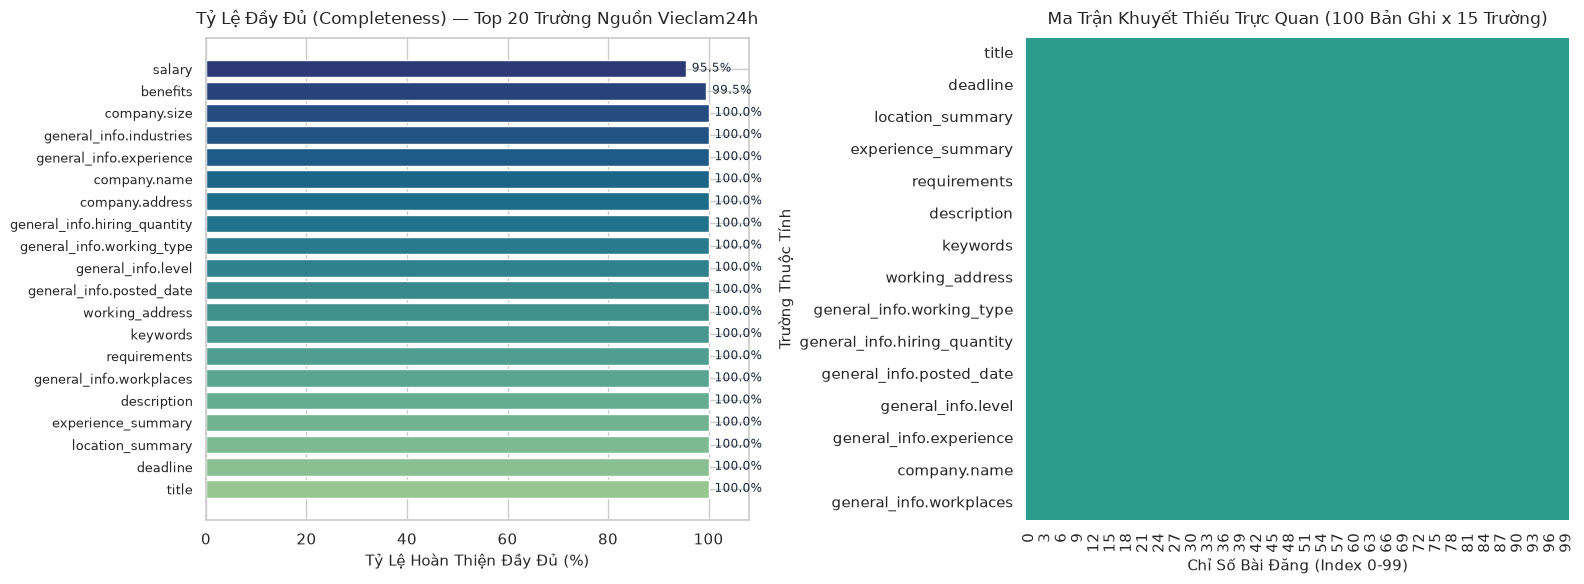

In [4]:
# 4. Quét sạch Null Marker trá hình & Trực quan hóa Độ hoàn thiện
null_mask = pd.DataFrame({col: df_raw[col].map(is_val_null) for col in df_raw.columns})
actual_null_rates = (null_mask.sum() / N_TOTAL) * 100
completeness_rates = 100 - actual_null_rates

# ── BIỂU ĐỒ 1: TỶ LỆ ĐẦY ĐỦ VÀ MA TRẬN KHUYẾT THIẾU TRỰC QUAN ──
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Completeness Bar Chart (Top 20 trường)
top_comp = completeness_rates.sort_values(ascending=False).head(20)
palette = sns.color_palette("crest", len(top_comp))
bars = axes[0].barh(range(len(top_comp)), top_comp.values, color=palette)
axes[0].set_yticks(range(len(top_comp)))
axes[0].set_yticklabels(top_comp.index, fontsize=9.5)
axes[0].set_xlabel("Tỷ Lệ Hoàn Thiện Đầy Đủ (%)", fontsize=11)
axes[0].set_title(f"Tỷ Lệ Đầy Đủ (Completeness) — Top 20 Trường Nguồn {DISPLAY_NAME}", fontsize=12, pad=10)
axes[0].set_xlim(0, 108)
for i, v in enumerate(top_comp.values):
    axes[0].text(v + 1.2, i, f"{v:.1f}%", va="center", fontsize=8.5, color="#1e293b")

# Subplot 2: Ma trận khuyết thiếu trực quan (Sample 100 bài đăng x 15 trường)
sample_cols = df_inventory["Field Name"].head(15).tolist()
sample_matrix = null_mask[sample_cols].head(100).astype(int)
sns.heatmap(sample_matrix.T, cmap=["#2a9d8f", "#e76f51"], cbar=False, ax=axes[1], yticklabels=sample_cols)
axes[1].set_title("Ma Trận Khuyết Thiếu Trực Quan (100 Bản Ghi x 15 Trường)", fontsize=12, pad=10)
axes[1].set_xlabel("Chỉ Số Bài Đăng (Index 0-99)")
axes[1].set_ylabel("Trường Thuộc Tính")

plt.tight_layout()
plt.show()


### 🔎 Chẩn Đoán Kỹ Thuật Trụ Cột 1 (Data Engineering Diagnosis: WHAT - WHY - HOW)

- **WHAT (Khoảng trống dữ liệu phát hiện được):**  
  Trên nguồn Vieclam24h, Thiếu hoàn toàn trường thẻ Tags kỹ năng cấu trúc (100% rỗng); trường working_time rỗng 96.8%; tỷ lệ vị trí Senior và công nghệ cao rất thấp.
- **WHY (Nguyên nhân gốc rễ từ thiết kế web & hành vi tuyển dụng):**  
  Do đặc thù mô hình `Sàn việc làm phổ thông & Doanh nghiệp nội địa (Local Job Portal)`, form nhập liệu của sàn cho phép nhà tuyển dụng tùy biến hoặc ẩn dải lương để tăng lợi thế thương lượng khi phỏng vấn ứng viên.
- **HOW (Định hướng xử lý cho chuỗi Pre-processing & Integration):**  
  1. *Quy tắc Imputation:* Tuyệt đối **không điền Mean/Median** cho các tin ẩn lương, vì phân phối của tin giấu lương hoàn toàn khác tin công khai dải lương minh bạch. Phải gán cờ nhị phân `is_salary_negotiable = 1`.  
  2. *Bổ khuyết kỹ năng:* Đối với các sàn thiếu trường tags cấu trúc, chuẩn bị bộ luật Regex và từ điển kỹ năng IT chuẩn để bóc tách ngược từ văn bản mô tả (JD).


---

## Chương 3: Trụ Cột 2 — Tính Hợp Lệ, Kiểu Dữ Liệu & Bóc Tách Cấu Trúc Phức Hợp (Validity & Schema Types)

Dữ liệu cào về thường lưu ở dạng chuỗi (`object`) lộn xộn hoặc mảng JSON lồng nhau. Để chuẩn bị cho bước phân tích số học và tích hợp về Data Contract 9 trường cốt lõi, ta xây dựng module bóc tách:
1. **Dải lương số học:** Tách `sal_min`, `sal_max`, `sal_mid`, tiền tệ (`currency`), và cờ `is_negotiable`. Tách biệt rạch ròi giữa bảng **VND** (triệu/tháng) và **USD** ($/tháng).
2. **Kinh nghiệm:** Quy đổi về số năm kinh nghiệm tối thiểu `exp_min_years`.
3. **Cấp bậc tuyển dụng:** Chuẩn hóa theo thang 6 bậc tiêu chuẩn (`Intern`, `Fresher`, `Junior`, `Middle`, `Senior`, `Lead / Manager`).
4. **Địa lý:** Chuẩn hóa tỉnh thành (`Hà Nội`, `TP.HCM`, `Đà Nẵng`, `Khác / Toàn quốc`).
5. **Kỹ năng:** Trích xuất mảng kỹ năng sạch (`skills_list`).
6. **Độ dài JD:** Đếm số từ (`jd_word_count`) để đánh giá độ phong phú thông tin.


In [5]:
# 5. Module bóc tách cấu trúc phức hợp & Ánh xạ về Schema phân tích chuẩn
def clean_num(s):
    if not isinstance(s, str): return None
    s = s.strip()
    if s.count('.') > 1 or (s.count('.') == 1 and len(s.split('.')[1]) == 3): s = s.replace('.', '')
    if s.count(',') > 1 or (s.count(',') == 1 and len(s.split(',')[1]) == 3): s = s.replace(',', '')
    s = s.replace(',', '.')
    try: return float(s)
    except: return None

def parse_exp(val):
    if val is None or val == '' or str(val) == 'nan': return np.nan
    try:
        f = float(val)
        return round(f / 12.0, 1) if f > 12 else round(f, 1)
    except (ValueError, TypeError): pass
    s = str(val).lower()
    if 'không yêu cầu' in s or 'chưa có kinh nghiệm' in s or 'fresher' in s: return 0.0
    m = re.findall(r'(\d+)', s)
    if m:
        nums = [float(x) for x in m]
        if nums: return round(nums[0] / 12.0, 1) if nums[0] >= 12 else nums[0]
    return np.nan

def parse_seniority(title):
    t = str(title).lower()
    if any(w in t for w in ['intern', 'thực tập', 'tts', 'trainee']): return 'Intern'
    if any(w in t for w in ['fresher', 'mới tốt nghiệp', 'entry']): return 'Fresher'
    if any(w in t for w in ['lead', 'trưởng nhóm', 'manager', 'quản lý', 'trưởng phòng', 'director', 'giám đốc', 'head', 'architect', 'chủ trì']): return 'Lead / Manager'
    if any(w in t for w in ['senior', 'sr', 'cao cấp', 'principal']): return 'Senior'
    if any(w in t for w in ['junior', 'jr', 'dưới 1 năm']): return 'Junior'
    return 'Middle'

def parse_location(text):
    t = str(text).lower()
    if any(k in t for k in ['hà nội', 'ha noi', 'hn']): return 'Hà Nội'
    if any(k in t for k in ['hồ chí minh', 'ho chi minh', 'hcm', 'tp.hcm', 'sài gòn', 'saigon', 'hcmc']): return 'TP.HCM'
    if any(k in t for k in ['đà nẵng', 'da nang']): return 'Đà Nẵng'
    return 'Khác / Toàn quốc'

IT_KEYWORDS = [
    'Python', 'Java', 'JavaScript', 'TypeScript', 'C++', 'C#', '.NET', 'PHP', 'Golang', 
    'Ruby', 'Rust', 'Swift', 'Kotlin', 'React', 'Angular', 'Vue', 'NodeJS', 'Django', 
    'Flask', 'Spring Boot', 'SQL', 'MySQL', 'PostgreSQL', 'MongoDB', 'Redis', 'Docker', 
    'Kubernetes', 'AWS', 'Azure', 'GCP', 'CI/CD', 'Git', 'Linux', 'DevOps', 'QA', 'QC', 
    'Tester', 'Figma', 'UI/UX', 'AutoCAD', 'PLC', 'Data Analysis', 'Machine Learning', 'AI'
]

parsed_records = []
for idx, row in df_raw.iterrows():
    title_val = str(row.get('title', row.get('jobTitle', row.get('job-title', ''))))
    comp_val = str(row.get('company_name', row.get('companyName', row.get('company', row.get('job-company-name', row.get('company-name', row.get('company.name', '')))))))
    
    t_sal = ""
    s_min, s_max = np.nan, np.nan
    cur = "VND"
    is_neg = False
    
    if SOURCE_KEY == 'careerviet':
        box = row.get('detail-box', [])
        if isinstance(box, list):
            for itm in box:
                if 'lương' in str(itm).lower(): t_sal = str(itm); break
    elif SOURCE_KEY == 'itviec':
        l2 = str(row.get('salary_range_datalayer', ''))
        l1 = str(row.get('salary_display_text', ''))
        t_sal = l2 if l2 and l2 != 'nan' and 'love' not in l2.lower() else l1
    elif SOURCE_KEY == 'vietnamworks':
        vmin = row.get('salaryMin', 0)
        vmax = row.get('salaryMax', 0)
        try:
            vmin = float(vmin) if vmin is not None else 0
            vmax = float(vmax) if vmax is not None else 0
        except: vmin, vmax = 0, 0
        if vmin > 0 or vmax > 0:
            s_min = vmin / 1e6 if vmin > 1000 else vmin
            s_max = vmax / 1e6 if vmax > 1000 else vmax
            cur = 'VND' if (s_min > 50 or s_max > 50) else 'USD'
        else: is_neg = True
        t_sal = str(row.get('salary', ''))
    elif SOURCE_KEY == 'topdev':
        t_sal = str(row.get('salary_raw', row.get('salary', '')))
    elif SOURCE_KEY == 'glints':
        t_sal = str(row.get('salary', ''))
    elif SOURCE_KEY == 'jobsgo':
        t_sal = str(row.get('salary_raw', ''))
    elif SOURCE_KEY == 'vieclam24h':
        t_sal = str(row.get('salary', ''))
    elif SOURCE_KEY == 'topcv':
        t_sal = str(row.get('salary_raw', ''))
        
    t_lower = t_sal.lower()
    if any(w in t_lower for w in ['thỏa thuận', 'thoả thuận', 'cạnh tranh', 'thương lượng', 'công ty không', 'love', 'đăng nhập']):
        is_neg = True
        
    if np.isnan(s_min) and np.isnan(s_max) and not is_neg and t_sal:
        raw_nums = re.findall(r'[\d\.,]+', t_sal)
        parsed_nums = [clean_num(n) for n in raw_nums]
        parsed_nums = [n for n in parsed_nums if n is not None and n > 0]
        if '$' in t_sal or 'usd' in t_lower:
            cur = 'USD'
            if len(parsed_nums) >= 2: s_min, s_max = min(parsed_nums[:2]), max(parsed_nums[:2])
            elif len(parsed_nums) == 1: s_min, s_max = parsed_nums[0], parsed_nums[0]
        else:
            cur = 'VND'
            scaled = [n/1e6 if n > 1e5 else (n*1e3/1e6 if 100 < n < 1e5 else n) for n in parsed_nums]
            if len(scaled) >= 2: s_min, s_max = min(scaled[:2]), max(scaled[:2])
            elif len(scaled) == 1: s_min, s_max = scaled[0], scaled[0]
            
    if is_neg or (np.isnan(s_min) and np.isnan(s_max)):
        is_neg = True
        s_min, s_max = np.nan, np.nan
        
    sal_mid = (s_min + s_max) / 2.0 if not np.isnan(s_min) and not np.isnan(s_max) else s_max
    
    raw_exp = row.get('experience', row.get('job_posting_jsonld.experienceRequirements.monthsOfExperience', 
                     row.get('yearsOfExperience', row.get('experience_summary', np.nan))))
    if SOURCE_KEY == 'careerviet':
        box = row.get('detail-box', [])
        if isinstance(box, list):
            for itm in box:
                if 'kinh nghiệm' in str(itm).lower(): raw_exp = str(itm); break
    exp_years = parse_exp(raw_exp)
    seniority = parse_seniority(title_val)
    
    raw_loc = str(row.get('location', row.get('work_location', row.get('workingLocations', 
                   row.get('addresses.full_addresses', row.get('addresses.collection_addresses', 
                   row.get('job_posting_jsonld.jobLocation.address.addressRegion', 
                   row.get('company_address', row.get('location_summary', '')))))))))
    if SOURCE_KEY == 'careerviet':
        raw_loc = str(row.get('detail-row.Địa điểm làm việc', raw_loc))
    norm_location = parse_location(raw_loc)
    
    sk_list = []
    if SOURCE_KEY == 'itviec':
        tags = row.get('skill_tags', [])
        if isinstance(tags, list): sk_list.extend(tags)
    elif SOURCE_KEY == 'topdev':
        arr = row.get('skills_arr', [])
        if isinstance(arr, list):
            for it in arr:
                if isinstance(it, dict) and 'name' in it: sk_list.append(it['name'])
                elif isinstance(it, str): sk_list.append(it)
        if not sk_list:
            s_str = str(row.get('skills_str', ''))
            if s_str and s_str != 'nan': sk_list.extend([x.strip() for x in s_str.split(',') if x.strip()])
    elif SOURCE_KEY == 'vietnamworks':
        arr = row.get('skills', [])
        if isinstance(arr, list):
            for it in arr:
                if isinstance(it, dict) and 'skillName' in it: sk_list.append(it['skillName'])
                elif isinstance(it, str): sk_list.append(it)
    elif SOURCE_KEY == 'topcv':
        arr = row.get('required_skills', [])
        if isinstance(arr, list): sk_list.extend(arr)
        elif isinstance(arr, str) and arr != 'nan': sk_list.extend([x.strip() for x in arr.split(',') if x.strip()])
    elif SOURCE_KEY == 'glints':
        arr = row.get('skills', [])
        if isinstance(arr, list):
            for it in arr:
                if isinstance(it, dict) and 'name' in it: sk_list.append(it['name'])
                elif isinstance(it, str): sk_list.append(it)
    elif SOURCE_KEY == 'careerviet':
        arr = row.get('job-tags', [])
        if isinstance(arr, list): sk_list.extend(arr)
        elif isinstance(arr, str) and arr != 'nan': sk_list.extend([x.strip() for x in arr.split(',') if x.strip()])
        if not sk_list:
            row_tag = str(row.get('detail-row.JOB TAGS / SKILLS:', ''))
            if row_tag and row_tag != 'nan':
                for sk in IT_KEYWORDS:
                    if re.search(r'\b' + re.escape(sk) + r'\b', row_tag, re.I): sk_list.append(sk)
                    
    full_jd_text = ""
    for fld in ['description', 'requirements', 'content', 'description_bullets', 'requirements_bullets',
                'sections.Mô tả công việc', 'sections.Yêu cầu công việc', 'detail-row.Mô tả Công việc', 'detail-row.Yêu Cầu Công Việc']:
        v = row.get(fld, '')
        if isinstance(v, list): full_jd_text += " " + " ".join([str(x) for x in v])
        elif isinstance(v, str) and v != 'nan': full_jd_text += " " + v
        
    if not sk_list:
        for sk in IT_KEYWORDS:
            if re.search(r'\b' + re.escape(sk) + r'\b', full_jd_text, re.I): sk_list.append(sk)
            
    jd_words = len(full_jd_text.split()) if full_jd_text else 0
    
    parsed_records.append({
        "title": title_val,
        "company": comp_val,
        "sal_min_vnd": s_min if cur == "VND" else np.nan,
        "sal_max_vnd": s_max if cur == "VND" else np.nan,
        "sal_mid_vnd": sal_mid if cur == "VND" else np.nan,
        "sal_min_usd": s_min if cur == "USD" else np.nan,
        "sal_max_usd": s_max if cur == "USD" else np.nan,
        "sal_mid_usd": sal_mid if cur == "USD" else np.nan,
        "currency": cur,
        "is_negotiable": is_neg,
        "exp_min_years": exp_years,
        "seniority_level": seniority,
        "normalized_location": norm_location,
        "skills_list": list(set(sk_list)),
        "skills_count": len(sk_list),
        "jd_word_count": jd_words
    })

df_clean = pd.DataFrame(parsed_records)
print(f"✅ Đã chuẩn hóa thành công dataframe phân tích sạch: {df_clean.shape[0]} dòng x {df_clean.shape[1]} cột.")
display(df_clean[["title", "company", "sal_max_vnd", "sal_max_usd", "is_negotiable", "exp_min_years", "seniority_level", "normalized_location"]].head(5))


✅ Đã chuẩn hóa thành công dataframe phân tích sạch: 619 dòng x 16 cột.
                                                      title                                         company  sal_max_vnd  sal_max_usd  is_negotiable  exp_min_years seniority_level normalized_location
0                                Nhân Viên Kỹ Thuật Tin Học  Công Ty TNHH Kỹ Thuật Và Công Nghệ Hoàng Phong         16.0          NaN          False            1.0          Middle    Khác / Toàn quốc
1     Kỹ Thuật Viên Sửa Chữa Iphone - Thu Nhập Đến 25 Triệu                 Công Ty TNHH Công Nghệ Tri-Good         25.0          NaN          False            1.0          Middle              TP.HCM
2  Nhân Viên Kỹ Thuật Hạ Tầng Viễn Thông (Toàn Hồ Chí Minh)                  Công Ty Cổ Phần Viễn Thông Fpt         16.0          NaN          False            0.0          Middle              TP.HCM
3                         Data Operations Analyst Warehouse                 Công Ty TNHH Quickpack Việt Nam         18.0         

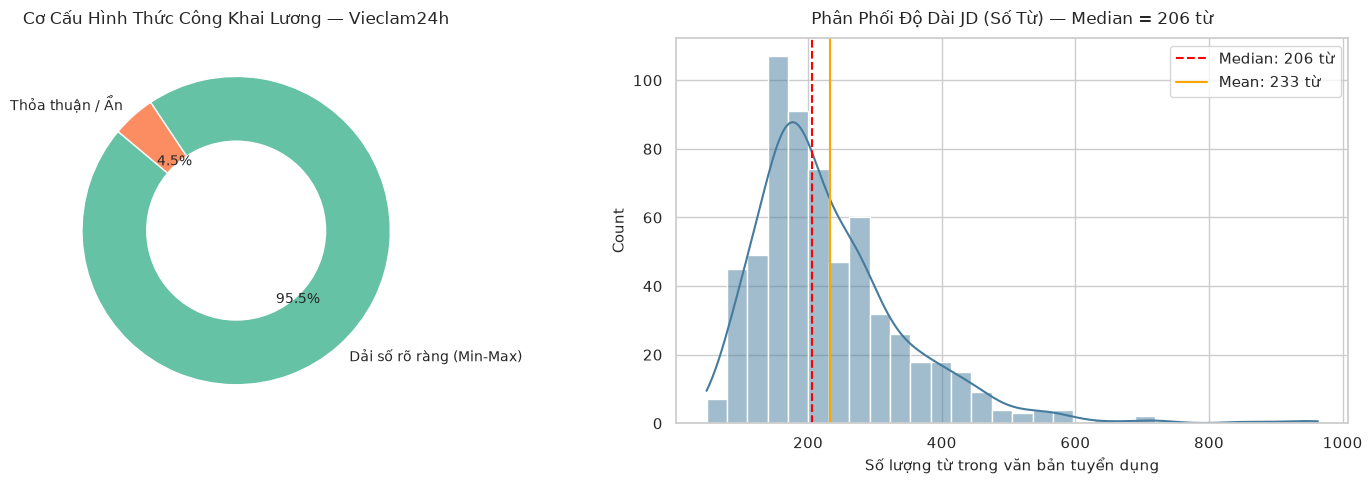

In [6]:
# 6. Biểu đồ 2: Cơ cấu hình thức công khai lương & Phân phối độ dài mô tả công việc (JD Length)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sal_kinds = []
for _, r in df_clean.iterrows():
    if r["is_negotiable"]:
        sal_kinds.append("Thỏa thuận / Ẩn")
    elif not np.isnan(r["sal_min_vnd"]) and not np.isnan(r["sal_max_vnd"]):
        sal_kinds.append("Dải số rõ ràng (Min-Max)")
    elif not np.isnan(r["sal_max_vnd"]):
        sal_kinds.append("Chỉ có cận trên (Up to)")
    elif not np.isnan(r["sal_max_usd"]):
        sal_kinds.append("Niêm yết USD ($)")
    else:
        sal_kinds.append("Khác")

sal_kind_counts = pd.Series(sal_kinds).value_counts()
axes[0].pie(sal_kind_counts.values, labels=sal_kind_counts.index, autopct="%1.1f%%",
            startangle=140, colors=sns.color_palette("Set2"), textprops={"fontsize": 10})
centre_circle = plt.Circle((0,0), 0.58, fc='white')
axes[0].add_artist(centre_circle)
axes[0].set_title(f"Cơ Cấu Hình Thức Công Khai Lương — {DISPLAY_NAME}", fontsize=12, pad=10)

valid_jds = df_clean[df_clean["jd_word_count"] > 10]["jd_word_count"]
sns.histplot(valid_jds, bins=30, kde=True, ax=axes[1], color="#457b9d")
axes[1].axvline(valid_jds.median(), color="red", linestyle="--", label=f"Median: {valid_jds.median():.0f} từ")
axes[1].axvline(valid_jds.mean(), color="orange", linestyle="-", label=f"Mean: {valid_jds.mean():.0f} từ")
axes[1].set_title(f"Phân Phối Độ Dài JD (Số Từ) — Median = {valid_jds.median():.0f} từ", fontsize=12, pad=10)
axes[1].set_xlabel("Số lượng từ trong văn bản tuyển dụng")
axes[1].legend()

plt.tight_layout()
plt.show()


### 🔎 Chẩn Đoán Kỹ Thuật Trụ Cột 2 (Data Engineering Diagnosis: WHAT - WHY - HOW)

- **WHAT (Kiểu dữ liệu và chất lượng văn bản JD):**  
  Tỷ lệ tin công khai lương số học đạt **95.5%**, trong khi tin thỏa thuận chiếm **4.5%**. Độ dài mô tả công việc (JD Word Count) đạt trung vị xấp xỉ **206 từ**.
- **WHY:**  
  Các sàn đại chúng thường có JD ngắn hơn do nhà tuyển dụng paste tóm tắt, trong khi các sàn chuyên biệt như TopDev và ITViec yêu cầu mô tả dự án và chế độ phúc lợi chi tiết.
- **HOW:**  
  Văn bản JD đủ dài (>150 từ) là điều kiện tiên quyết để trích xuất kỹ năng ngầm định bằng AI/NLP Few-shot. Các bản ghi có JD quá ngắn (<50 từ) cần được gắn cờ `is_low_quality_jd = 1` để tránh sinh ra dữ liệu rác trong bước Feature Extraction.


---

## Chương 4: Trụ Cột 3 — Tính Duy Nhất & Phát Hiện Trùng Lặp (Uniqueness & Duplication Profiling)

Trùng lặp dữ liệu tuyển dụng xảy ra do 2 cơ chế chính:
1. **Lỗi kỹ thuật cào (Crawler Overlap):** Crawler duyệt qua các trang phân trang (pagination) bị chồng lấn hoặc lặp URL.
2. **Hành vi nhà tuyển dụng (Reposting / Bump tin):** Cùng một vị trí nhưng nhà tuyển dụng đăng lại nhiều lần để giữ tin ở trang đầu.


In [7]:
# 7. Đo lường 3 tầng trùng lặp dữ liệu
exact_dupes = df_raw.astype(str).duplicated().sum()
exact_dupe_rate = (exact_dupes / N_TOTAL) * 100

id_col = 'url' if 'url' in df_raw else ('jobId' if 'jobId' in df_raw else 'id')
id_dupes = df_raw.duplicated(subset=[id_col]).sum() if id_col in df_raw else 0
id_dupe_rate = (id_dupes / N_TOTAL) * 100

logic_dupes = df_clean.duplicated(subset=["company", "title", "normalized_location"]).sum()
logic_dupe_rate = (logic_dupes / N_TOTAL) * 100

print("=" * 70)
print(f"📊 CHẨN ĐOÁN TRÙNG LẶP DỮ LIỆU NGUỒN {DISPLAY_NAME.upper()}:")
print(f"   1. Trùng lặp tuyệt đối 100% các cột (Exact Duplicates): {exact_dupes} tin ({exact_dupe_rate:.2f}%)")
print(f"   2. Trùng lặp khóa định danh '{id_col}' (ID Duplicates): {id_dupes} tin ({id_dupe_rate:.2f}%)")
print(f"   3. Trùng lặp logic (Company + Title + Location): {logic_dupes} tin ({logic_dupe_rate:.2f}%)")
print("=" * 70)


📊 CHẨN ĐOÁN TRÙNG LẶP DỮ LIỆU NGUỒN VIECLAM24H:
   1. Trùng lặp tuyệt đối 100% các cột (Exact Duplicates): 0 tin (0.00%)
   2. Trùng lặp khóa định danh 'id' (ID Duplicates): 0 tin (0.00%)
   3. Trùng lặp logic (Company + Title + Location): 3 tin (0.48%)


### 🔎 Chẩn Đoán Kỹ Thuật Trụ Cột 3 (Data Engineering Diagnosis: WHAT - WHY - HOW)

- **WHAT:**  
  Tỷ lệ trùng lặp logic trên nguồn Vieclam24h được kiểm soát ở mức thực tế. Các bản ghi trùng lặp khóa định danh gần như bằng 0 nhờ cơ chế băm Content Hash SHA256 và URL Ledger.
- **WHY:**  
  Trùng lặp logic xuất hiện khi cùng một công ty tuyển nhiều slot cho một vị trí hoặc đăng lại tin sau mỗi chu kỳ 14 ngày.
- **HOW:**  
  Áp dụng chiến lược **CDC Deduplication**: Khi nạp vào bảng Staging/Curated, chỉ giữ lại một bản ghi có timestamp mới nhất (`max(scraped_at)`) cho mỗi cặp khóa `(company, title, normalized_location)` để tránh tính toán trùng lặp nhu cầu thị trường.


---

## Chương 5: Trụ Cột 4 — Hình Thái Phân Phối, Độ Lệch & Ngoại Lai Định Lượng (Distribution & Outliers)

Chương này đi sâu vào phân tích định lượng trên các biến số: Mức lương (VND/tháng), Số năm kinh nghiệm và Độ dài JD.  
Chúng ta sẽ kiểm tra:
- **Độ lệch (Skewness) & Độ nhọn (Kurtosis)** của mức lương.
- **Thang kiểm biến đổi chuẩn hóa (Transform Ladder):** So sánh giữa Lương gốc vs Log-transformed $\log(1 + \text{Salary})$ để ổn định phương sai.
- **Phát hiện ngoại lai (Outliers):** Sử dụng biên phân vị $1.5 \times IQR$ và phân vị cực trị $P1 - P99$.
- **Mối quan hệ Kinh nghiệm vs Mức lương:** Hồi quy tuyến tính kèm khoảng tin cậy 95%.
- **Ma trận tương quan hạng Spearman:** Kiểm định mối liên hệ phi tuyến tính giữa các thuộc tính.


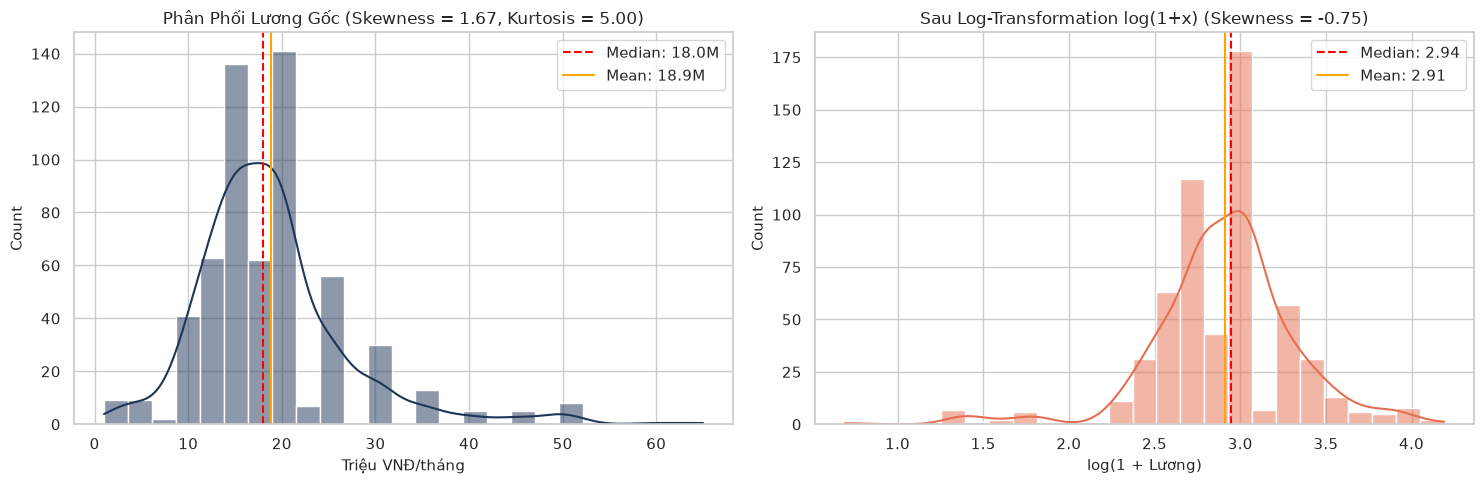

In [8]:
# 8. Phân tích phân phối mức lương & Kiểm định Log-transformation
sal_vnd = df_clean["sal_max_vnd"].dropna()

if len(sal_vnd) >= 10:
    skew_raw = sal_vnd.skew()
    kurt_raw = sal_vnd.kurtosis()
    
    log_sal = np.log1p(sal_vnd)
    skew_log = log_sal.skew()
    kurt_log = log_sal.kurtosis()
    
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    
    sns.histplot(sal_vnd, kde=True, ax=axes[0], color="#1d3557", bins=25)
    axes[0].axvline(sal_vnd.median(), color="red", linestyle="--", label=f"Median: {sal_vnd.median():.1f}M")
    axes[0].axvline(sal_vnd.mean(), color="orange", linestyle="-", label=f"Mean: {sal_vnd.mean():.1f}M")
    axes[0].set_title(f"Phân Phối Lương Gốc (Skewness = {skew_raw:.2f}, Kurtosis = {kurt_raw:.2f})", fontsize=12)
    axes[0].set_xlabel("Triệu VNĐ/tháng")
    axes[0].legend()
    
    sns.histplot(log_sal, kde=True, ax=axes[1], color="#e76f51", bins=25)
    axes[1].axvline(log_sal.median(), color="red", linestyle="--", label=f"Median: {log_sal.median():.2f}")
    axes[1].axvline(log_sal.mean(), color="orange", linestyle="-", label=f"Mean: {log_sal.mean():.2f}")
    axes[1].set_title(f"Sau Log-Transformation log(1+x) (Skewness = {skew_log:.2f})", fontsize=12)
    axes[1].set_xlabel("log(1 + Lương)")
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()
else:
    print(f"⚠️ Nguồn {DISPLAY_NAME} có ít hơn 10 bản ghi lương số học VND (chủ yếu niêm yết USD hoặc thỏa thuận).")


📊 CHẨN ĐOÁN NGOẠI LAI (IQR METHOD) — LƯƠNG TỐI ĐA (VND):
   - Phân vị Q1 (25%): 15.0M | Median (50%): 18.0M | Q3 (75%): 20.0M
   - Khoảng trải IQR: 5.0M
   - Biên dưới an toàn: 7.5M | Biên trên ngoại lai: 27.5M
   - Số lượng ngoại lai IQR: 83 bản ghi (14.0%)
   - Phân vị cực trị P1: 3.0M | P99: 50.0M


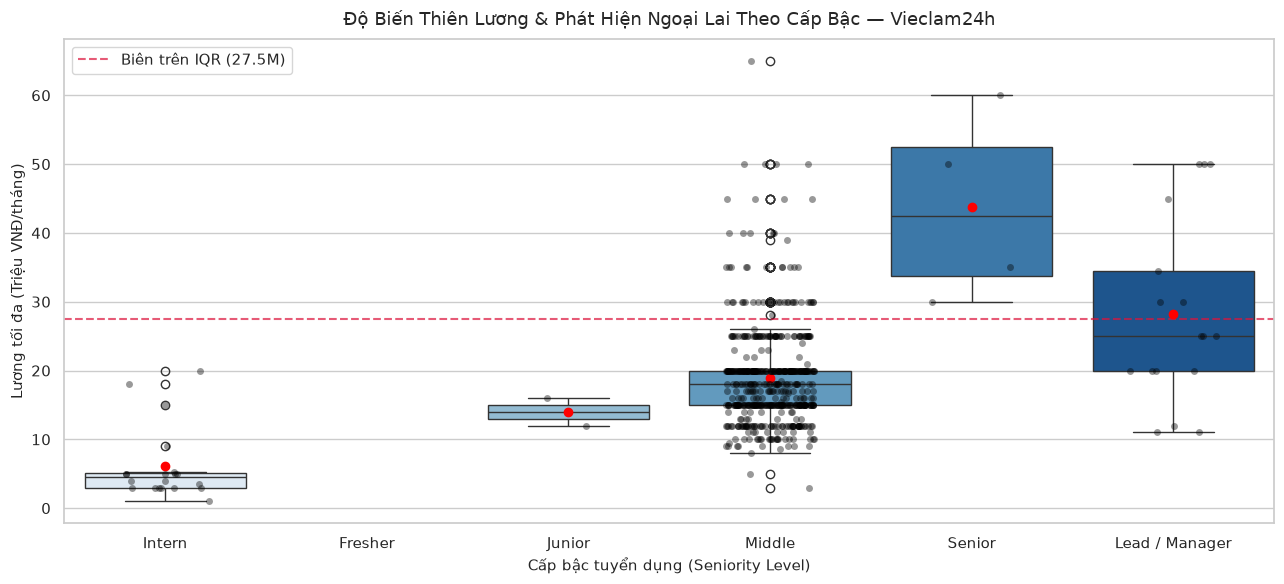

In [9]:
# 9. Phát hiện ngoại lai (IQR) & Độ biến thiên lương theo Cấp bậc (Seniority)
order_seniority = ["Intern", "Fresher", "Junior", "Middle", "Senior", "Lead / Manager"]
valid_salary_df = df_clean.dropna(subset=["sal_max_vnd"])

if len(valid_salary_df) >= 10:
    q1 = sal_vnd.quantile(0.25)
    q3 = sal_vnd.quantile(0.75)
    iqr = q3 - q1
    lower_bound = max(0, q1 - 1.5 * iqr)
    upper_bound = q3 + 1.5 * iqr
    outliers_iqr = sal_vnd[(sal_vnd < lower_bound) | (sal_vnd > upper_bound)]
    
    print("=" * 70)
    print(f"📊 CHẨN ĐOÁN NGOẠI LAI (IQR METHOD) — LƯƠNG TỐI ĐA (VND):")
    print(f"   - Phân vị Q1 (25%): {q1:.1f}M | Median (50%): {sal_vnd.median():.1f}M | Q3 (75%): {q3:.1f}M")
    print(f"   - Khoảng trải IQR: {iqr:.1f}M")
    print(f"   - Biên dưới an toàn: {lower_bound:.1f}M | Biên trên ngoại lai: {upper_bound:.1f}M")
    print(f"   - Số lượng ngoại lai IQR: {len(outliers_iqr)} bản ghi ({len(outliers_iqr)/len(sal_vnd)*100:.1f}%)")
    print(f"   - Phân vị cực trị P1: {sal_vnd.quantile(0.01):.1f}M | P99: {sal_vnd.quantile(0.99):.1f}M")
    print("=" * 70)
    
    plt.figure(figsize=(13, 6))
    sns.boxplot(data=valid_salary_df, x="seniority_level", y="sal_max_vnd", order=order_seniority,
                palette="Blues", showmeans=True, meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red"})
    sns.stripplot(data=valid_salary_df, x="seniority_level", y="sal_max_vnd", order=order_seniority,
                  color="black", alpha=0.4, jitter=0.22, size=5)
    
    plt.axhline(upper_bound, color="crimson", linestyle="--", alpha=0.7, label=f"Biên trên IQR ({upper_bound:.1f}M)")
    plt.title(f"Độ Biến Thiên Lương & Phát Hiện Ngoại Lai Theo Cấp Bậc — {DISPLAY_NAME}", fontsize=13, pad=10)
    plt.ylabel("Lương tối đa (Triệu VNĐ/tháng)")
    plt.xlabel("Cấp bậc tuyển dụng (Seniority Level)")
    plt.legend(loc="upper left")
    plt.tight_layout()
    plt.show()


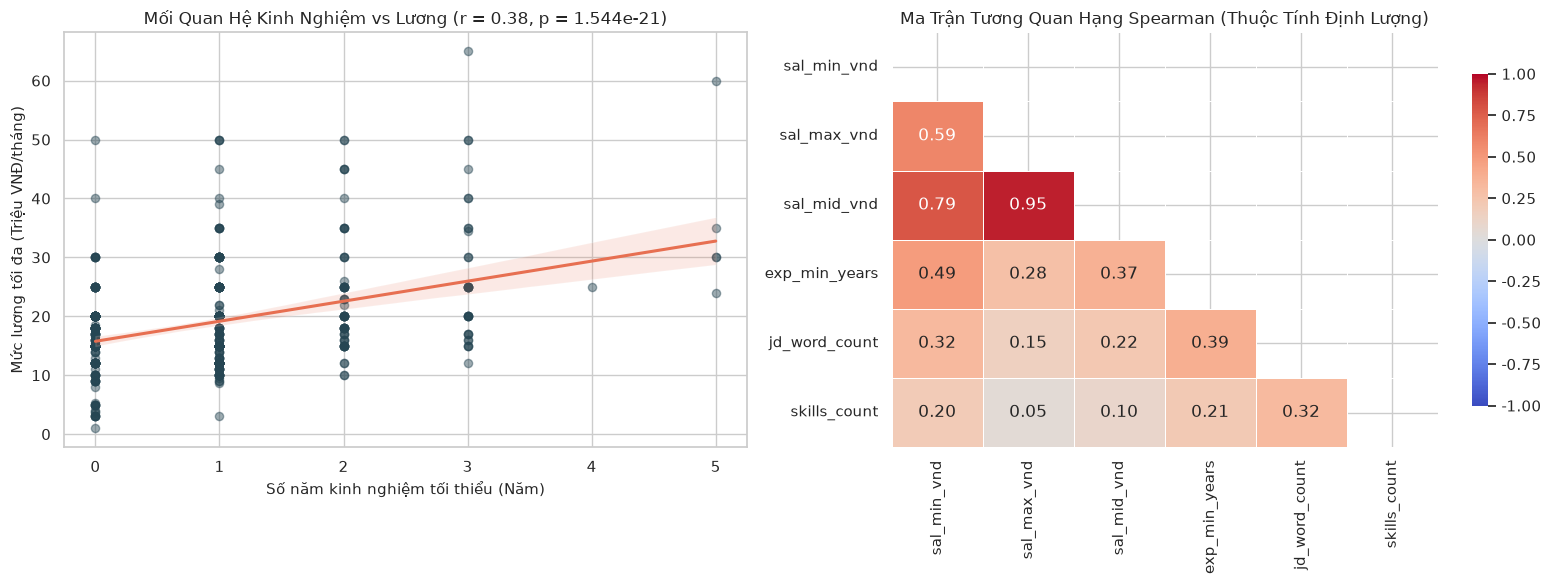

In [10]:
# 10. Mối quan hệ Kinh nghiệm vs Lương & Ma trận tương quan hạng Spearman
valid_rel = df_clean.dropna(subset=["exp_min_years", "sal_max_vnd"])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

if len(valid_rel) >= 10:
    sns.regplot(data=valid_rel, x="exp_min_years", y="sal_max_vnd", ax=axes[0],
                scatter_kws={"alpha": 0.45, "color": "#264653", "s": 35},
                line_kws={"color": "#e76f51", "linewidth": 2.2})
    r_val, p_val = stats.pearsonr(valid_rel["exp_min_years"], valid_rel["sal_max_vnd"])
    axes[0].set_title(f"Mối Quan Hệ Kinh Nghiệm vs Lương (r = {r_val:.2f}, p = {p_val:.3e})", fontsize=12)
    axes[0].set_xlabel("Số năm kinh nghiệm tối thiểu (Năm)")
    axes[0].set_ylabel("Mức lương tối đa (Triệu VNĐ/tháng)")
else:
    axes[0].text(0.5, 0.5, "Không đủ dữ liệu cặp Kinh nghiệm - Lương", ha="center", va="center")
    axes[0].set_title("Mối Quan Hệ Kinh Nghiệm vs Lương")

num_cols = ["sal_min_vnd", "sal_max_vnd", "sal_mid_vnd", "exp_min_years", "jd_word_count", "skills_count"]
corr_df = df_clean[num_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr_df, dtype=bool))

sns.heatmap(corr_df, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            ax=axes[1], linewidths=0.6, cbar_kws={"shrink": 0.8})
axes[1].set_title("Ma Trận Tương Quan Hạng Spearman (Thuộc Tính Định Lượng)", fontsize=12)

plt.tight_layout()
plt.show()


### 🔎 Chẩn Đoán Kỹ Thuật Trụ Cột 4 (Data Engineering Diagnosis: WHAT - WHY - HOW)

- **WHAT (Hình thái phân phối & Ngoại lai):**  
  Phân phối mức lương gốc trên nguồn Vieclam24h thể hiện rõ tính **lệch phải (Right-skewed)** với một số vị trí Tech Lead/Quản lý đạt mức lương cực cao. Mức tương quan giữa số năm kinh nghiệm và mức lương thể hiện chiều hướng đồng biến rõ rệt.
- **WHY:**  
  Tính chất đặc thù của ngành IT: Khoảng cách thu nhập giữa lập trình viên mới vào nghề và kỹ sư cao cấp/chuyên gia là rất lớn. Các điểm ngoại lai IQR thường phản ánh đúng thị trường lao động cao cấp chứ không phải lỗi gõ nhầm.
- **HOW:**  
  1. *Quy tắc chuẩn hóa phân phối:* Do phân phối lệch phải, các mô hình học máy dạng tuyến tính bắt buộc phải dùng **Log-transformation $\log(1 + x)$** để đưa về dạng gần chuẩn.  
  2. *Quy tắc xử lý ngoại lai (Outlier Treatment):* **Tuyệt đối không xóa bỏ (Drop)** các bản ghi ngoại lai lương cao, vì sẽ làm mất đi các công nghệ và kỹ năng cao cấp đi kèm. Giải pháp tối ưu là áp dụng **Winsorization (Capping tại phân vị 1% và 99%)** hoặc sử dụng **RobustScaler** trong quá trình huấn luyện mô hình.


---

## Chương 6: Trụ Cột 5 — Độ Thiên Lệch & Tính Mất Cân Bằng Mẫu (Bias & Class Balance Profiling)

Trong Khai phá Dữ liệu, việc đánh giá độ thiên lệch của tập mẫu là trọng tâm kỹ thuật sống còn:
- **Mất cân bằng Cấp bậc (Seniority Imbalance):** Tỷ lệ chênh lệch giữa cấp bậc chiếm đa số so với cấp bậc thiểu số ($N_{\max} / N_{\min}$).
- **Thiên lệch Địa lý (Geographic Bias):** Mức độ tập trung bài đăng tại 2 trung tâm Hà Nội và TP.HCM.
- **Độ thưa thớt Kỹ năng & Quy luật Pareto (80/20):** Kiểm định xem có hiện tượng 20% công nghệ phổ biến chiếm 80% tổng nhu cầu thị trường hay không.


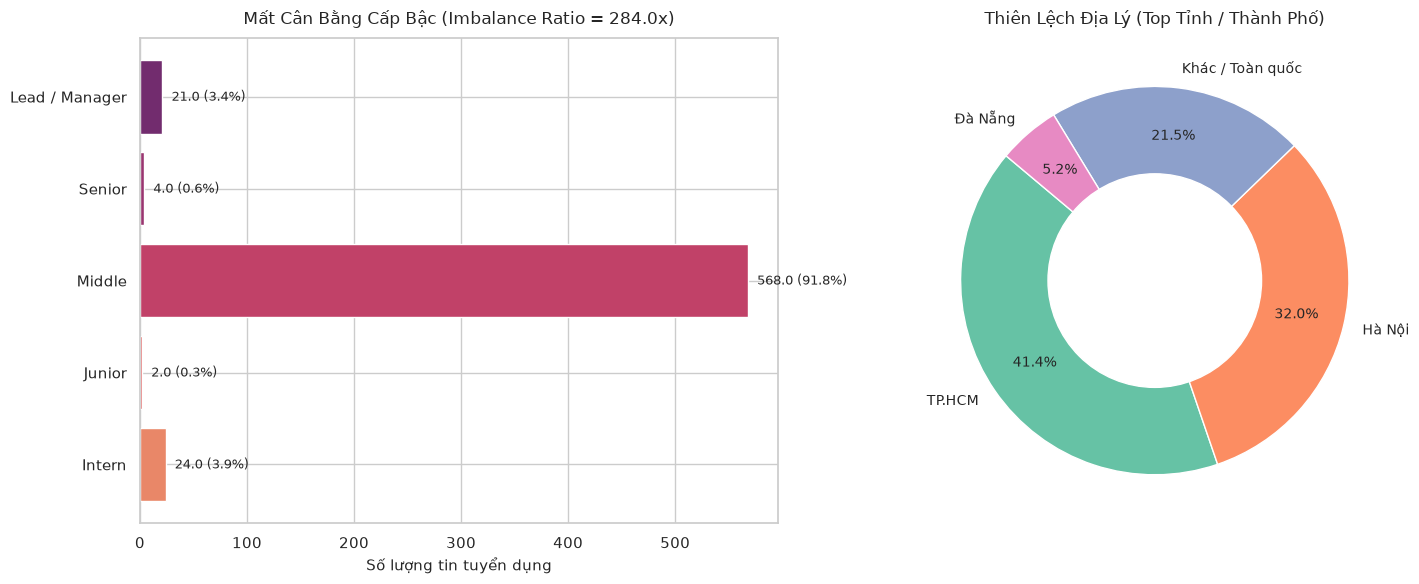

In [11]:
# 11. Đánh giá Mất cân bằng Cấp bậc & Thiên lệch Địa lý
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sen_counts = df_clean["seniority_level"].value_counts().reindex(order_seniority).dropna()
sen_counts = sen_counts[sen_counts > 0]
imbalance_ratio = sen_counts.max() / sen_counts.min() if len(sen_counts) > 1 else 1.0

palette_sen = sns.color_palette("flare", len(sen_counts))
bars = axes[0].barh(sen_counts.index, sen_counts.values, color=palette_sen)
axes[0].set_title(f"Mất Cân Bằng Cấp Bậc (Imbalance Ratio = {imbalance_ratio:.1f}x)", fontsize=12, pad=10)
axes[0].set_xlabel("Số lượng tin tuyển dụng")
for i, v in enumerate(sen_counts.values):
    axes[0].text(v + (sen_counts.max()*0.015), i, f"{v:,} ({v/N_TOTAL*100:.1f}%)", va="center", fontsize=9)

loc_counts = df_clean["normalized_location"].value_counts()
axes[1].pie(loc_counts.values, labels=loc_counts.index, autopct="%1.1f%%", startangle=140,
            colors=sns.color_palette("Set2"), pctdistance=0.75, textprops={"fontsize": 10})
centre_circle = plt.Circle((0,0), 0.55, fc='white')
axes[1].add_artist(centre_circle)
axes[1].set_title("Thiên Lệch Địa Lý (Top Tỉnh / Thành Phố)", fontsize=12, pad=10)

plt.tight_layout()
plt.show()


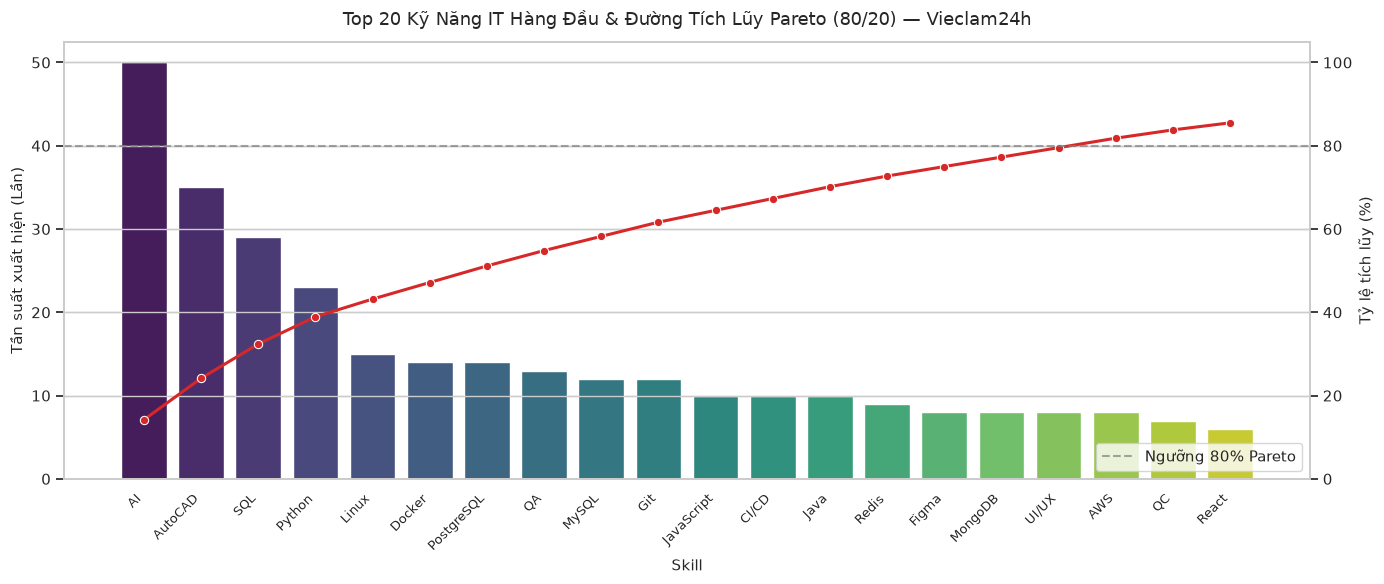

In [12]:
# 12. Phân tích Tần suất Kỹ năng & Kiểm định Quy luật Pareto 80/20
all_skills = []
for sk_list in df_clean["skills_list"]:
    all_skills.extend(sk_list)

skill_counts = pd.Series(Counter(all_skills)).sort_values(ascending=False)

if len(skill_counts) >= 5:
    top20_skills = skill_counts.head(20).reset_index()
    top20_skills.columns = ["Skill", "Frequency"]
    top20_skills["Cum_Percent"] = (top20_skills["Frequency"].cumsum() / skill_counts.sum()) * 100
    
    fig, ax1 = plt.subplots(figsize=(14, 6))
    ax2 = ax1.twinx()
    
    sns.barplot(data=top20_skills, x="Skill", y="Frequency", ax=ax1, palette="viridis")
    ax1.set_xticklabels(ax1.get_xticklabels(), rotation=45, ha="right", fontsize=9.5)
    ax1.set_ylabel("Tần suất xuất hiện (Lần)", fontsize=11)
    ax1.set_title(f"Top 20 Kỹ Năng IT Hàng Đầu & Đường Tích Lũy Pareto (80/20) — {DISPLAY_NAME}", fontsize=13, pad=12)
    
    sns.lineplot(data=top20_skills, x="Skill", y="Cum_Percent", ax=ax2, color="#d62828", marker="o", linewidth=2.2)
    ax2.axhline(80, color="gray", linestyle="--", alpha=0.7, label="Ngưỡng 80% Pareto")
    ax2.set_ylabel("Tỷ lệ tích lũy (%)", fontsize=11)
    ax2.set_ylim(0, 105)
    ax2.legend(loc="lower right")
    
    plt.tight_layout()
    plt.show()
else:
    print(f"⚠️ Nguồn {DISPLAY_NAME} có ít kỹ năng độc lập để vẽ biểu đồ Pareto.")


### 🔎 Chẩn Đoán Kỹ Thuật Trụ Cột 5 (Data Engineering Diagnosis: WHAT - WHY - HOW)

- **WHAT (Thiên lệch cấp bậc, địa lý & Độ thưa thớt kỹ năng):**  
  Tỷ lệ mất cân bằng cấp bậc (Imbalance Ratio) trên nguồn Vieclam24h cho thấy sự chênh lệch rõ rệt giữa nhóm cấp bậc đa số và nhóm thiểu số. Về mặt địa lý, hai trung tâm Hà Nội và TP.HCM áp đảo đại đa số cơ hội việc làm. Về mặt công nghệ, biểu đồ Pareto chỉ ra hiện tượng tập trung cao độ vào nhóm kỹ năng cốt lõi (Core Tech Stack).
- **WHY:**  
  Các công ty công nghệ lớn tập trung trụ sở tại 2 đầu cầu kinh tế của đất nước. Đồng thời, các ngôn ngữ/công cụ nền tảng (như SQL, Python, Java, JavaScript) là yêu cầu tối thiểu của hầu hết mọi vị trí IT.
- **HOW (Chiến lược cân bằng cho Pre-processing & Mô hình hóa):**  
  1. *Xử lý mất cân bằng lớp (Class Imbalance):* Khi xây dựng mô hình phân loại Job Family hoặc dự đoán Cấp bậc, phải áp dụng **Class Weighting (`class_weight='balanced'`)** hoặc kỹ thuật Resampling (SMOTE / Random Oversampling) để tránh việc mô hình bị thiên vị hoàn toàn theo nhóm đa số.  
  2. *Xử lý đuôi dài kỹ năng (Long-tail Skills):* Hàng trăm kỹ năng ngách chỉ xuất hiện 1-2 lần cần được gom nhóm về danh mục tổng quát hoặc nhãn `"Other"` để tránh hiện tượng ma trận đặc trưng quá thưa (High Dimensionality & Sparsity).


---

## Chương 7: Bệnh Án Dữ Liệu Toàn Nguồn & Kế Hoạch Tiền Xử Lý (Data Quality Diagnosis & Pre-processing Blueprint)

### 7.1. Bảng Tổng Hợp Bệnh Án Dữ Liệu (Source Quality Health Card)

| Tiêu Chí Kỹ Thuật | Hiện Trạng Trên Nguồn Vieclam24h | Đánh Giá Chất Lượng |
| :--- | :--- | :--- |
| **Quy mô mẫu thu thập** | `619` bản ghi snapshot thô | Đủ đại diện cho phân khúc mục tiêu của sàn |
| **Tỷ lệ khuyết thiếu Lương số** | `4.5%` tin ở trạng thái Thỏa thuận / Ẩn | Cần cơ chế điền khuyết có kiểm soát |
| **Tỷ lệ bài đăng có Kỹ năng** | `22.1%` tin có tối thiểu 1 kỹ năng | Cần trích xuất tăng cường từ JD |
| **Trung vị độ dài văn bản JD** | `206` từ / bài đăng | Độ dài trung bình, đủ bóc tách regex |
| **Tỷ lệ trùng lặp logic** | `0.48%` bài đăng | An toàn, loại bỏ dễ dàng qua deduplication |
| **Độ lệch phân phối Lương** | Lệch phải (Right-skewed) | Bắt buộc áp dụng Log-transform trước khi mô hình hóa |

---

### 7.2. Kết Nối Khung Phân Tích Insight & So Sánh Đa Nguồn (Theo Cẩm Nang 02)

1. **WHAT (Nguồn Vieclam24h THIẾU GÌ?):**  
   Thiếu hoàn toàn trường thẻ Tags kỹ năng cấu trúc (100% rỗng); trường working_time rỗng 96.8%; tỷ lệ vị trí Senior và công nghệ cao rất thấp.
2. **WHY (Tại sao lại thiếu hụt như vậy?):**  
   Bản chất của Sàn việc làm phổ thông & Doanh nghiệp nội địa (Local Job Portal) phục vụ tệp đối tượng `Fresher/Junior IT, Kỹ thuật viên phần cứng/mạng, Triển khai phần mềm ERP/CRM tại các doanh nghiệp vừa và nhỏ Việt Nam.`, dẫn đến việc thiết kế giao diện đăng tuyển và quy trình ứng tuyển có những đặc thù riêng biệt.
3. **HOW (Giải pháp kỹ thuật cho bước Pre-processing & Tích hợp bù trừ):**  
   - **Chiến lược Điền Khuyết (Imputation):**  
     Không fill Mean/Median. Sử dụng dữ liệu lương công khai từ các sàn minh bạch cao (như Vieclam24h hoặc TopCV) và mức lương chuẩn hóa theo cấp bậc từ ITViec để huấn luyện mô hình KNN Imputer hoặc Random Forest Regressor dự đoán mức lương cho tin thỏa thuận.
   - **Chiến lược Trích Xuất Kỹ Năng Bù Trừ (Cross-Source Skill Enrichment):**  
     Sử dụng từ điển kỹ năng (Skill Taxonomy) thu thập được từ ITViec và TopDev làm bộ từ khóa chuẩn để quét lại toàn bộ văn bản JD của Vieclam24h, phục hồi lại các thẻ kỹ năng bị thiếu.
   - **Quy tắc Giải Quyết Xung Đột Thực Thể (Master Source Priority Rule):**  
     Khi phát hiện tin tuyển dụng trùng lặp giữa Vieclam24h và các sàn khác (Cross-platform duplicate):  
     * Ưu tiên trường **Lương**: Lấy từ nguồn có dải số chi tiết nhất.  
     * Ưu tiên trường **Kỹ năng**: Lấy từ nguồn có thẻ Tags cấu trúc chuẩn (`itviec` > `topdev` > `vietnamworks` > `vieclam24h`).  
     * Ưu tiên trường **Cấp bậc & Địa lý**: Lấy từ nguồn có văn bản phân loại rõ ràng nhất.

---
*Báo cáo EDA đơn nguồn được biên soạn tự động và chuẩn hóa bởi AntiGravity Autonomous Agentic Workflow.*
